<a href="https://colab.research.google.com/github/Bndreea/Team-9/blob/main/Group9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#*GROUP 9 PROJECT - Breast Cancer Project*

# **ANDREEA - Diagnostic Data Set (WDBC)**


[Dataset](/https://archive.ics.uci.edu/dataset/17/breast-cancer-wisconsin-diagnostic)

Summary:\
1.Data clean-up and visualisation\
2.Model selection\
3.Model training

# 1.Loading data

Loading the Wisconsin Breast Cancer Dataset from UCI Irvine.

In [ ]:
!pip install ucimlrepo
from ucimlrepo import fetch_ucirepo

# Fetch the Breast Cancer Wisconsin (Diagnostic) dataset
wdbc = fetch_ucirepo(id=17)

# Extract features and targets
x = wdbc.data.features
y = wdbc.data.targets

# Display information and preview
print("Diagnostic Features Shape:", x.shape)
display(x.head())
print("Diagnostic Targets Shape:", y.shape)
display(y.head())
print()
print("Information about features")
display(x.info())
display(x.describe())
print("Inforation about target")
display(y.info())
display(y.describe())

Diagnostic Features Shape: (569, 30)


,radius1,texture1,perimeter1,area1,smoothness1,compactness1,concavity1,concave_points1,symmetry1,fractal_dimension1,...,radius3,texture3,perimeter3,area3,smoothness3,compactness3,concavity3,concave_points3,symmetry3,fractal_dimension3
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


Diagnostic Targets Shape: (569, 1)


,Diagnosis
0,M
1,M
2,M
3,M
4,M



Information about features
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 30 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   radius1             569 non-null    float64
 1   texture1            569 non-null    float64
 2   perimeter1          569 non-null    float64
 3   area1               569 non-null    float64
 4   smoothness1         569 non-null    float64
 5   compactness1        569 non-null    float64
 6   concavity1          569 non-null    float64
 7   concave_points1     569 non-null    float64
 8   symmetry1           569 non-null    float64
 9   fractal_dimension1  569 non-null    float64
 10  radius2             569 non-null    float64
 11  texture2            569 non-null    float64
 12  perimeter2          569 non-null    float64
 13  area2               569 non-null    float64
 14  smoothness2         569 non-null    float64
 15  compactness2        569 non-n

None

,radius1,texture1,perimeter1,area1,smoothness1,compactness1,concavity1,concave_points1,symmetry1,fractal_dimension1,...,radius3,texture3,perimeter3,area3,smoothness3,compactness3,concavity3,concave_points3,symmetry3,fractal_dimension3
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,...,16.269190,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,...,4.833242,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,7.930000,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,13.010000,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,14.970000,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,18.790000,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,...,36.040000,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500


Inforation about target
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 1 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   Diagnosis  569 non-null    object
dtypes: object(1)
memory usage: 4.6+ KB


None

,Diagnosis
count,569
unique,2
top,B
freq,357


There are no missing values.

#2.Outliers

Plotting a box plot for the normalized 30 features to identify outliers.

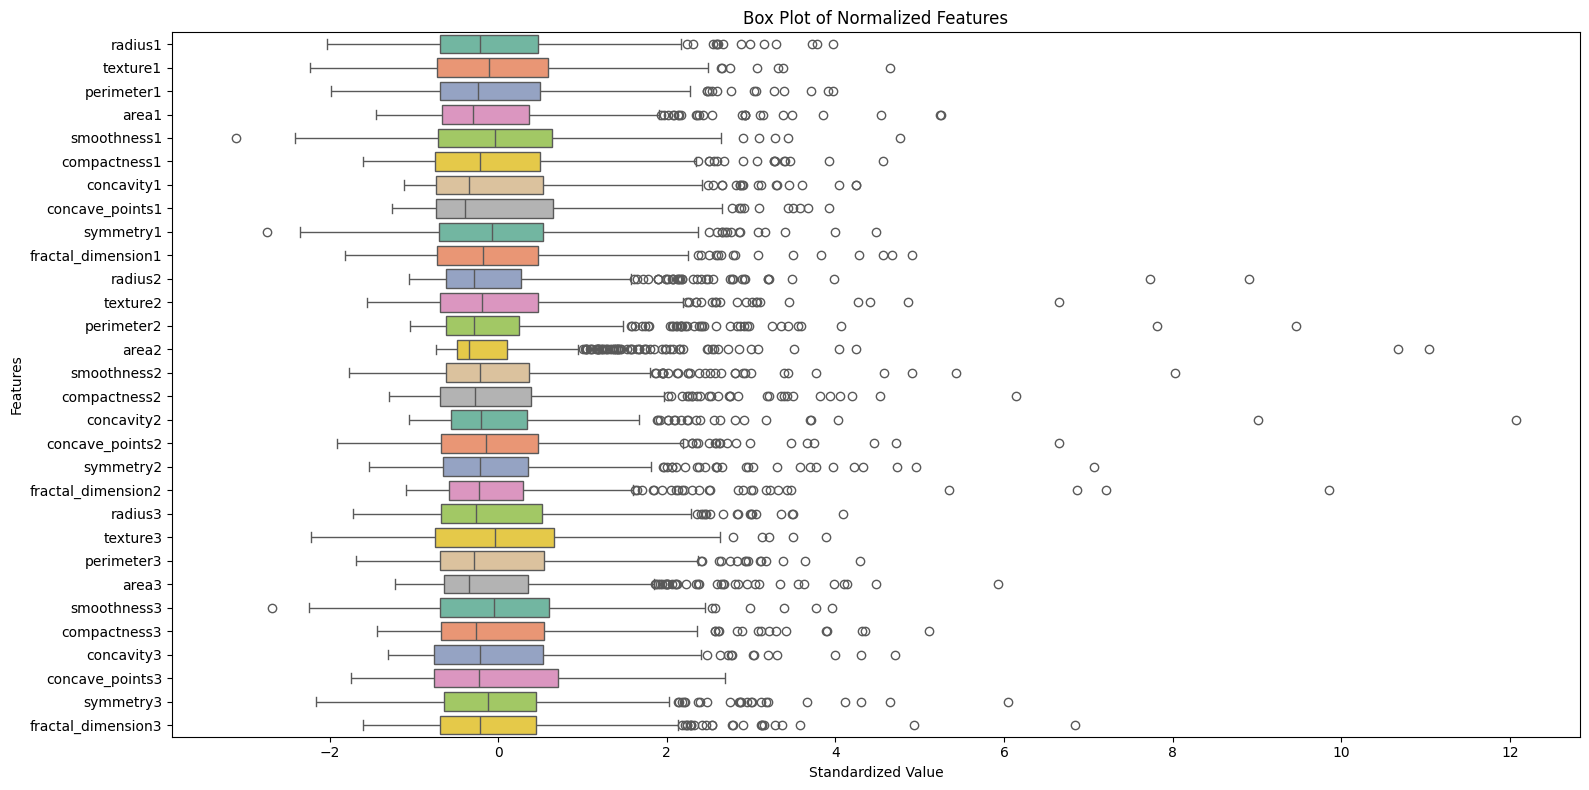

In [ ]:
from sklearn.preprocessing import StandardScaler
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Instantiate the scaler
scaler = StandardScaler()

# Select numeric columns (excluding any non-numeric fields if present)
numeric_cols = x.select_dtypes(include='number').columns

# Fit and transform the features
x_scaled_array = scaler.fit_transform(x[numeric_cols])
x_scaled = pd.DataFrame(x_scaled_array, columns=numeric_cols)

# Plot the box plot for the 30 scaled features
plt.figure(figsize=(16, 8))
sns.boxplot(data=x_scaled, orient='h', palette='Set2')
plt.title('Box Plot of Normalized Features')
plt.xlabel('Standardized Value')
plt.ylabel('Features')
plt.tight_layout()
plt.show()

What does one do with 1 billion outliers?

Plotting a bar graph representing the distribution of malignant and bening cases.

Diagnosis Value Counts:
Diagnosis
B    357
M    212
Name: count, dtype: int64
Ratios:
Malignant: 0.373
Benign: 0.627


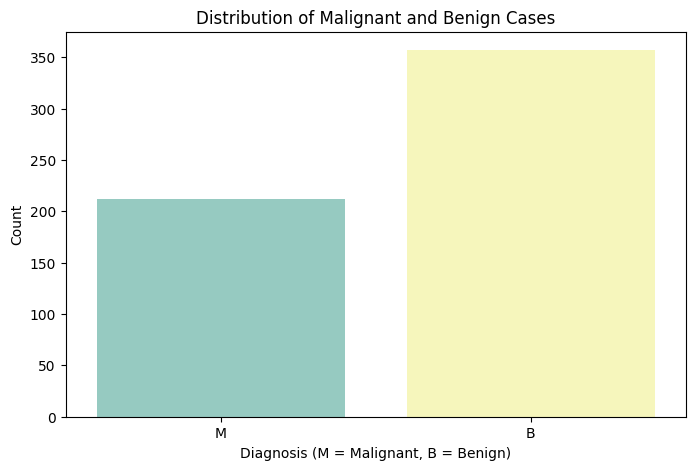

In [ ]:
import matplotlib.pyplot as plt

# Calculate class distribution
diagnosis_counts = y['Diagnosis'].value_counts()
print("Diagnosis Value Counts:")
print(diagnosis_counts)

print("Ratios:")
print(f"Malignant: {diagnosis_counts['M'] / (diagnosis_counts['B'] + diagnosis_counts['M']):.3g}")
print(f"Benign: {diagnosis_counts['B']/(diagnosis_counts["B"]+diagnosis_counts['M']):.3g}")

# Plotting
plt.figure(figsize=(8, 5))
sns.countplot(data=y, x='Diagnosis', palette='Set3', hue='Diagnosis', legend=False)
plt.title('Distribution of Malignant and Benign Cases')
plt.xlabel('Diagnosis (M = Malignant, B = Benign)')
plt.ylabel('Count')
plt.grid(False)
plt.show()

#3.Model Training

## 3.1 Logistic Regression Model

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    precision_recall_curve,
    auc,
    confusion_matrix,
    classification_report
)
import numpy as np

# Split the dataset into train and validation sets
# Map B to 0 and M to 1
x_train, x_val, y_train, y_val = train_test_split(
    x_scaled,
    y['Diagnosis'].map({'B': 0, 'M': 1}),
    test_size=0.2,
    random_state=42,
    stratify=y['Diagnosis']
)

# Instantiate and fit the Logistic Regression model
log_reg = LogisticRegression(random_state=42)
log_reg.fit(x_train, y_train)

# Predictions
y_pred = log_reg.predict(x_val)
y_pred_proba = log_reg.predict_proba(x_val)[:, 1]

# Convert y_val from strings ('B', 'M') to numeric (0, 1) if they are not already
y_val_numeric = y_val.map({'B': 0, 'M': 1}) if y_val.dtype == 'object' else y_val

# Calculate basic metrics
accuracy = accuracy_score(y_val_numeric, y_pred)
precision = precision_score(y_val_numeric, y_pred)
recall = recall_score(y_val_numeric, y_pred)
f1_weighted = f1_score(y_val_numeric, y_pred, average='weighted')

# Calculate specificity
tn, fp, fn, tp = confusion_matrix(y_val_numeric, y_pred).ravel()
specificity = tn / (tn + fp)

# Calculate Area Under Curves
roc_auc = roc_auc_score(y_val_numeric, y_pred_proba)
precisions, recalls, thresholds = precision_recall_curve(y_val_numeric, y_pred_proba)
pr_auc = auc(recalls, precisions)

# Print metrics
print(f"=== Model Evaluation Metrics ===")
print(f"Accuracy:         {accuracy:.4f}")
print(f"Precision:        {precision:.4f}")
print(f"Recall:           {recall:.4f}")
print(f"Specificity:      {specificity:.4f}")
print(f"F1-Score (Wtd):   {f1_weighted:.4f}")
print(f"ROC-AUC:          {roc_auc:.4f}")
print(f"PR-AUC:           {pr_auc:.4f}")
print(f"\n=== Confusion Matrix ===")
print(f"[[TN, FP],\n [FN, TP]]")
print(confusion_matrix(y_val_numeric, y_pred))


=== Model Evaluation Metrics ===
Accuracy:         0.9649
Precision:        0.9750
Recall:           0.9286
Specificity:      0.9861
F1-Score (Wtd):   0.9647
ROC-AUC:          0.9960
PR-AUC:           0.9942

=== Confusion Matrix ===
[[TN, FP],
 [FN, TP]]
[[71  1]
 [ 3 39]]


## 3.2 Random Forest


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    precision_recall_curve,
    auc,
    confusion_matrix
)

# Instantiate and fit the Random Forest model
rf_clf = RandomForestClassifier(random_state=42)
rf_clf.fit(x_train, y_train)

# Predictions
y_pred_rf = rf_clf.predict(x_val)
y_pred_proba_rf = rf_clf.predict_proba(x_val)[:, 1]

# Calculate metrics
accuracy_rf = accuracy_score(y_val, y_pred_rf)
precision_rf = precision_score(y_val, y_pred_rf)
recall_rf = recall_score(y_val, y_pred_rf)
f1_weighted_rf = f1_score(y_val, y_pred_rf, average='weighted')

# Calculate specificity
tn_rf, fp_rf, fn_rf, tp_rf = confusion_matrix(y_val, y_pred_rf).ravel()
specificity_rf = tn_rf / (tn_rf + fp_rf)

# Calculate Area Under Curves
roc_auc_rf = roc_auc_score(y_val, y_pred_proba_rf)
precisions_rf, recalls_rf, thresholds_rf = precision_recall_curve(y_val, y_pred_proba_rf)
pr_auc_rf = auc(recalls_rf, precisions_rf)

# Print metrics
print(f"=== Random Forest Model Evaluation Metrics ===")
print(f"Accuracy:         {accuracy_rf:.4f}")
print(f"Precision:        {precision_rf:.4f}")
print(f"Recall:           {recall_rf:.4f}")
print(f"Specificity:      {specificity_rf:.4f}")
print(f"F1-Score (Wtd):   {f1_weighted_rf:.4f}")
print(f"ROC-AUC:          {roc_auc_rf:.4f}")
print(f"PR-AUC:           {pr_auc_rf:.4f}")
print(f"\n=== Confusion Matrix ===")
print(f"[[TN, FP],\n [FN, TP]]")
print(confusion_matrix(y_val, y_pred_rf))

=== Random Forest Model Evaluation Metrics ===
Accuracy:         0.9737
Precision:        1.0000
Recall:           0.9286
Specificity:      1.0000
F1-Score (Wtd):   0.9735
ROC-AUC:          0.9929
PR-AUC:           0.9898

=== Confusion Matrix ===
[[TN, FP],
 [FN, TP]]
[[72  0]
 [ 3 39]]


## 3.3 Support Vector Machine

In [ ]:
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    precision_recall_curve,
    auc,
    confusion_matrix
)

# Instantiate and fit the SVM model
svm_clf= SVC(kernel='linear', random_state=42)

# Prediction
svm_clf.fit(x_train,y_train)
y_pred_svm=svm_clf.predict(x_val)
y_scores_svm = svm_clf.decision_function(x_val)

# Calculate basic metrics
accuracy_svm = accuracy_score(y_val, y_pred_svm)
precision_svm = precision_score(y_val, y_pred_svm)
recall_svm = recall_score(y_val, y_pred_svm)
f1_weighted_svm = f1_score(y_val, y_pred_svm, average='weighted')

# Calculate specificity
tn_svm, fp_svm, fn_svm, tp_svm = confusion_matrix(y_val, y_pred_svm).ravel()
safety_denom_spec = (tn_svm + fp_svm)
specificity_svm = tn_svm / safety_denom_spec if safety_denom_spec > 0 else 0.0

# Calculate Area Under Curves (ROC-AUC and PR-AUC) using decision scores
roc_auc_svm = roc_auc_score(y_val, y_scores_svm)
precisions_svm, recalls_svm, thresholds_svm = precision_recall_curve(y_val, y_scores_svm)
pr_auc_svm = auc(recalls_svm, precisions_svm)

# Print metrics
print(f"=== SVM Model Evaluation Metrics ===")
print(f"Accuracy:         {accuracy_svm:.4f}")
print(f"Precision:        {precision_svm:.4f}")
print(f"Recall:           {recall_svm:.4f}")
print(f"Specificity:      {specificity_svm:.4f}")
print(f"F1-Score (Wtd):   {f1_weighted_svm:.4f}")
print(f"ROC-AUC:          {roc_auc_svm:.4f}")
print(f"PR-AUC:           {pr_auc_svm:.4f}")
print(f"\n=== Confusion Matrix ===")
print(f"[[TN, FP],\n [FN, TP]]")
print(confusion_matrix(y_val, y_pred_svm))


=== SVM Model Evaluation Metrics ===
Accuracy:         0.9649
Precision:        1.0000
Recall:           0.9048
Specificity:      1.0000
F1-Score (Wtd):   0.9645
ROC-AUC:          0.9914
PR-AUC:           0.9880

=== Confusion Matrix ===
[[TN, FP],
 [FN, TP]]
[[72  0]
 [ 4 38]]


# **SEB - Prognostic Data Set (WPBC)**

*[dataset link](https://archive.ics.uci.edu/dataset/16/breast+cancer+wisconsin+prognostic)*

> The three measurements recorded in the dataset are:
>
> 1 - Mean Average
>
> 2 - Standard Error (SE)
>
> 3 - Worst (Mean of the 3 largest values)

(for example: radius2 = SE radius, area3 = Worst area)

##1: Data Loading
Use Python libraries to load and visualise the dataset:

**Pandas** - Data manipulation

**NumPy** - Numerical operations

**Matplotlib/Seaborn** - Visualisation using graphs

**ucimlrepo** - Specific library for accessing our required dataset

In [ ]:
!pip install ucimlrepo
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from ucimlrepo import fetch_ucirepo

The Wisconsin Prognostic Breast Cancer dataset was obtained from the UCI Machine Learning Repository (id=16). The dataset contains nuclear measurements from breast cancer patients with corresponding information on whether it was recurring.

In [ ]:
wpbc = fetch_ucirepo(id=16)
X = wpbc.data.features
#X represents the independent variables (the predictor variables/measurements)
Y = wpbc.data.targets
#Y represents the dependent varaibles (the target variable/outcome)

In [ ]:
print("Sizes of X (main table), Y (target table)")
print("X:", X.shape)
print("Y:", Y.shape)
print()
print("Column names, data types and missing values:")
print("X:")
X.info()
print()
print("Y:")
Y.info()
print()
print("X table")
display(X)
print("X statistics summary")
display(X.describe())

Sizes of X (main table), Y (target table)
X: (198, 33)
Y: (198, 1)

Column names, data types and missing values:
X:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 198 entries, 0 to 197
Data columns (total 33 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Time                198 non-null    int64  
 1   radius1             198 non-null    float64
 2   texture1            198 non-null    float64
 3   perimeter1          198 non-null    float64
 4   area1               198 non-null    float64
 5   smoothness1         198 non-null    float64
 6   compactness1        198 non-null    float64
 7   concavity1          198 non-null    float64
 8   concave_points1     198 non-null    float64
 9   symmetry1           198 non-null    float64
 10  fractal_dimension1  198 non-null    float64
 11  radius2             198 non-null    float64
 12  texture2            198 non-null    float64
 13  perimeter2          198 non-null    flo

,Time,radius1,texture1,perimeter1,area1,smoothness1,compactness1,concavity1,concave_points1,symmetry1,...,perimeter3,area3,smoothness3,compactness3,concavity3,concave_points3,symmetry3,fractal_dimension3,tumor_size,lymph_node_status
0,31,18.02,27.60,117.50,1013.0,0.09489,0.10360,0.10860,0.07055,0.1865,...,139.70,1436.0,0.11950,0.1926,0.3140,0.11700,0.2677,0.08113,5.0,5.0
1,61,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,0.2419,...,184.60,2019.0,0.16220,0.6656,0.7119,0.26540,0.4601,0.11890,3.0,2.0
2,116,21.37,17.44,137.50,1373.0,0.08836,0.11890,0.12550,0.08180,0.2333,...,159.10,1949.0,0.11880,0.3449,0.3414,0.20320,0.4334,0.09067,2.5,0.0
3,123,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,0.2597,...,98.87,567.7,0.20980,0.8663,0.6869,0.25750,0.6638,0.17300,2.0,0.0
4,27,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,0.1809,...,152.20,1575.0,0.13740,0.2050,0.4000,0.16250,0.2364,0.07678,3.5,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
193,10,22.52,21.92,146.90,1597.0,0.07592,0.09162,0.06862,0.06367,0.1728,...,162.10,1902.0,0.08191,0.1319,0.1056,0.09378,0.2061,0.05788,6.0,2.0
194,8,15.44,31.18,101.00,740.4,0.09399,0.10620,0.13750,0.06500,0.1735,...,112.60,929.0,0.12720,0.2362,0.2975,0.12860,0.2914,0.08024,1.5,0.0
195,12,17.17,29.19,110.00,915.3,0.08952,0.06655,0.06583,0.05068,0.1793,...,132.50,1295.0,0.12610,0.1572,0.2141,0.09520,0.3362,0.06033,3.7,0.0
196,3,21.42,22.84,145.00,1440.0,0.10700,0.19390,0.23800,0.13180,0.1884,...,198.30,2375.0,0.14980,0.4379,0.5411,0.22150,0.2832,0.08981,3.0,NaN


X statistics summary


,Time,radius1,texture1,perimeter1,area1,smoothness1,compactness1,concavity1,concave_points1,symmetry1,...,perimeter3,area3,smoothness3,compactness3,concavity3,concave_points3,symmetry3,fractal_dimension3,tumor_size,lymph_node_status
count,198.000000,198.000000,198.00000,198.000000,198.000000,198.000000,198.000000,198.000000,198.000000,198.000000,...,198.000000,198.000000,198.000000,198.000000,198.000000,198.000000,198.000000,198.000000,198.000000,194.000000
mean,46.732323,17.412323,22.27601,114.856566,970.040909,0.102681,0.142648,0.156243,0.086776,0.192754,...,140.347778,1404.958586,0.143921,0.365102,0.436685,0.178778,0.323404,0.090828,2.847475,3.211340
std,34.462870,3.161676,4.29829,21.383402,352.149215,0.012522,0.049898,0.070572,0.033877,0.027437,...,28.892279,586.006972,0.022004,0.163965,0.173625,0.045181,0.075161,0.021172,1.937964,5.479276
min,1.000000,10.950000,10.38000,71.900000,361.600000,0.074970,0.046050,0.023980,0.020310,0.130800,...,85.100000,508.100000,0.081910,0.051310,0.023980,0.028990,0.156500,0.055040,0.400000,0.000000
25%,14.000000,15.052500,19.41250,98.160000,702.525000,0.093900,0.110200,0.106850,0.063670,0.174075,...,118.075000,947.275000,0.129325,0.248700,0.322150,0.152650,0.275950,0.076577,1.500000,0.000000
50%,39.500000,17.290000,21.75000,113.700000,929.100000,0.101900,0.131750,0.151350,0.086075,0.189350,...,136.500000,1295.000000,0.141850,0.351300,0.402350,0.179250,0.310300,0.086890,2.500000,1.000000
75%,72.750000,19.580000,24.65500,129.650000,1193.500000,0.110975,0.172200,0.200500,0.103925,0.209325,...,159.875000,1694.250000,0.154875,0.423675,0.541050,0.207125,0.358800,0.101375,3.500000,4.000000
max,125.000000,27.220000,39.28000,182.100000,2250.000000,0.144700,0.311400,0.426800,0.201200,0.304000,...,232.200000,3903.000000,0.222600,1.058000,1.170000,0.290300,0.663800,0.207500,10.000000,27.000000


##2: Data Cleanup
[1] Remove unnecessary columns:

- "ID" (doesn't contain important data)
  
- "Outcome" (this hides the value that the models will try to predict)
  
- "Time" (could mislead the models with data representing two slightly different things)

[2] Check for duplicate rows

[3] Fill in the missing values to not throw away data points

In [ ]:
print(X.columns.tolist())

['Time', 'radius1', 'texture1', 'perimeter1', 'area1', 'smoothness1', 'compactness1', 'concavity1', 'concave_points1', 'symmetry1', 'fractal_dimension1', 'radius2', 'texture2', 'perimeter2', 'area2', 'smoothness2', 'compactness2', 'concavity2', 'concave_points2', 'symmetry2', 'fractal_dimension2', 'radius3', 'texture3', 'perimeter3', 'area3', 'smoothness3', 'compactness3', 'concavity3', 'concave_points3', 'symmetry3', 'fractal_dimension3', 'tumor_size', 'lymph_node_status']


Apparently the "ID" and "Outcome" columns don't appear which is good, so I just have to remove the "Time" column.

Also checking for any duplicate rows in the main dataset, and missing values in the outcomes.

In [ ]:
X = X.drop(columns=["Time"])
print(X.shape)
print(X.isna().sum())
print()
print("Duplicate rows:", X.duplicated().sum())
print("Missing outcomes:", Y.isna().sum().sum())

(198, 32)
radius1               0
texture1              0
perimeter1            0
area1                 0
smoothness1           0
compactness1          0
concavity1            0
concave_points1       0
symmetry1             0
fractal_dimension1    0
radius2               0
texture2              0
perimeter2            0
area2                 0
smoothness2           0
compactness2          0
concavity2            0
concave_points2       0
symmetry2             0
fractal_dimension2    0
radius3               0
texture3              0
perimeter3            0
area3                 0
smoothness3           0
compactness3          0
concavity3            0
concave_points3       0
symmetry3             0
fractal_dimension3    0
tumor_size            0
lymph_node_status     4
dtype: int64

Duplicate rows: 0
Missing outcomes: 0


So there are only 4 N/A values, all in the "lymph_node_status" column.

There are also no duplicate rows, so we don't have to remove any rows.

I'll fill in the missing values during the preprocessing using imputation as to not skew the data.

##3: Count Outcomes
Check the outomes and visualise them in a graph to check whether the data is balanced.

Outcome
N          151
R           47
Name: count, dtype: int64



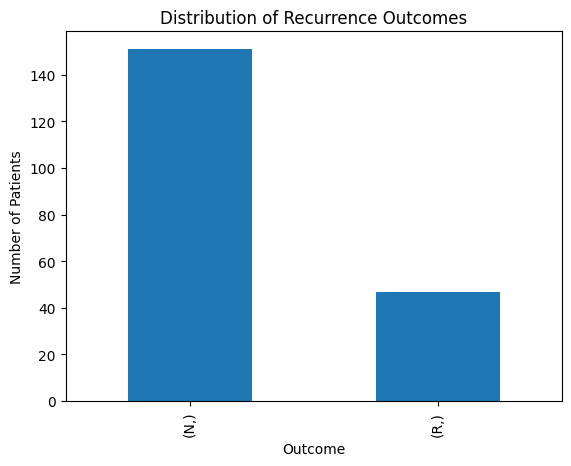

In [ ]:
print(Y.value_counts())
print()
Y.value_counts().plot(kind="bar")
plt.title("Distribution of Recurrence Outcomes")
plt.xlabel("Outcome")
plt.ylabel("Number of Patients")
plt.show()

This graph shows a clear imbalance: roughly 3 out of every 4 patients did not experience recurrence.

> This means we have to focus especially on: Recall, precision, F1-score and PR-AUC.

##4: EDA (Comparison of Measurements)
Below, I'll plot a few box plots measuring key characteristics with whether recurrence happened or not.
>I'll choose Mean Radius, Mean Concavity, and SE of Symmetry

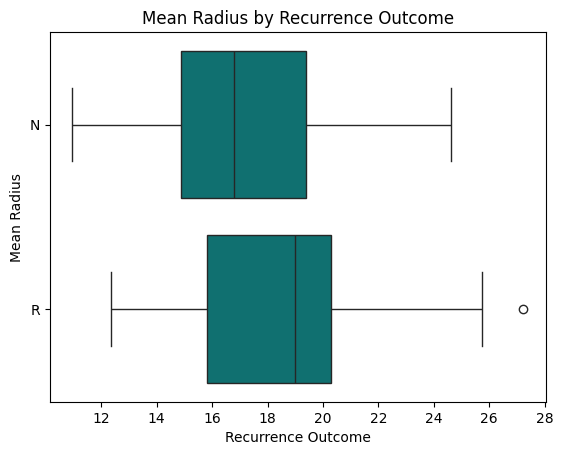

In [ ]:
sns.boxplot(x=X["radius1"],y=Y.iloc[:,0],color="teal")
plt.title("Mean Radius by Recurrence Outcome")
plt.xlabel("Recurrence Outcome")
plt.ylabel("Mean Radius")
plt.show()

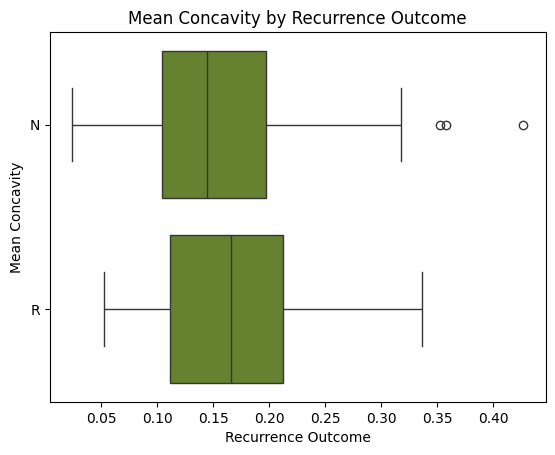

In [ ]:
sns.boxplot(x=X["concavity1"],y=Y.iloc[:,0],color="olivedrab")
plt.title("Mean Concavity by Recurrence Outcome")
plt.xlabel("Recurrence Outcome")
plt.ylabel("Mean Concavity")
plt.show()

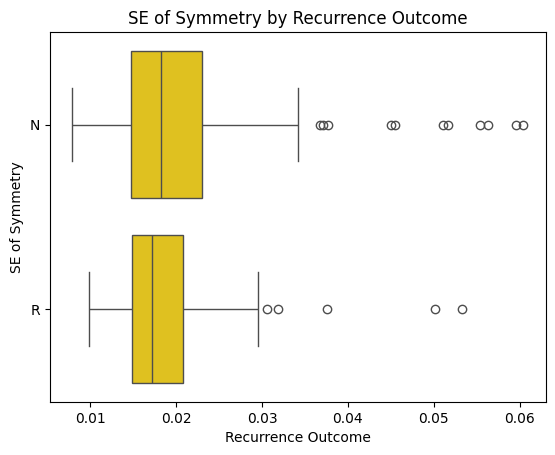

In [ ]:
sns.boxplot(x=X["symmetry2"],y=Y.iloc[:,0],color="gold")
plt.title("SE of Symmetry by Recurrence Outcome")
plt.xlabel("Recurrence Outcome")
plt.ylabel("SE of Symmetry")
plt.show()

##5: Preprocessing
Make some changes to the data so the data models are able to read it properly:
> - Seperate target variable (Convert N -> 0 (no recurrence) and R -> 1 (recurrence))
>
>- Use scikit-learn to import the model tools
>
>- Remove columns to match with the WDBC dataset
>
>- Seperate the cohort into stratified groups

In [ ]:
#converts the outcomes from N -> 0, R -> 1
Y = Y.iloc[:,0].map({"N":0,"R":1})
print(Y.value_counts())

Outcome
0    151
1     47
Name: count, dtype: int64


In [ ]:
#the preprocesses
from sklearn.preprocessing import StandardScaler #standardises numerical features
from sklearn.pipeline import Pipeline #runs preprocessing steps and the model in sequence

#the models
from sklearn.linear_model import LogisticRegression #predicts probability of a binary outcome
from sklearn.ensemble import RandomForestClassifier #combines many decision trees to make predictions
from sklearn.svm import SVC #Support Vector Classifier

#evaluation
from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_predict #trains and evaluates a model across multiple folds
from sklearn.metrics import confusion_matrix #used to calculate specificity
from sklearn.metrics import ConfusionMatrixDisplay #to visualise the confusion matrices

The WPBC dataset has 2 extra columns: "tumor_size" and "lymph_node_status", so to match the WDBC dataset with the models, I need to remove those columns.

In [ ]:
X_nuclear = X.drop(columns=["tumor_size","lymph_node_status"])
print(X_nuclear.shape) #should be (198, 30) now

(198, 30)


Actually, since the Lymph Node Status column was the only column which had missing values, and now we've removed that column to match the models in the first dataset (WDBC), the preprocessing now has to only include standardising the data.

In [ ]:
#creates a process to standardise the data
preprocessing = Pipeline([
    ("scaler", StandardScaler())
])

Since the data is not very balanced, using stratified cross-validation will make the models more efficient and accurate.

>Since there are 198 patients, using a 5-fold validation gives about 40 patients per group, and around 10 of them having recurrence.
>
>The models will train on 4 groups, then test on the remaining group

In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

##6: The Models
> 1: Logistic Regression
>
> 2: Random Forest
>
> 3: SVM

###6.1: Logistic Regression

In [ ]:
#logistic regression pipeline
log_reg = Pipeline([
    ("preprocessing", preprocessing),
    ("model", LogisticRegression(max_iter=1000))
])

#evaluation model
lg_results = cross_validate(
    log_reg,
    X_nuclear,
    Y,
    cv=cv,
    scoring=["accuracy","precision","recall","f1","roc_auc","average_precision"]
)

#calculate basic metrics
print("Logistic Regression Model Evaluation Metrics")
print("--------------------------------------------")
metricnames = ["Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC", "PR-AUC"]
metrickeys = ["test_accuracy", "test_precision", "test_recall", "test_f1", "test_roc_auc", "test_average_precision"]
for name, metric in zip(metricnames, metrickeys):
  scores = lg_results[metric]
  print(f"{name}: {scores.mean():.3f} ± {scores.std():.3f}")

#predictions
lg_Y_pred = cross_val_predict(log_reg, X_nuclear, Y, cv=cv)

#calculate specificity using the confusion matrix
tn, fp, fn, tp = confusion_matrix(Y, lg_Y_pred).ravel()
lg_specificity = tn/(tn+fp)
print("Specificity:",round(lg_specificity,3))
print("Confusion Matrix:")
print(confusion_matrix(Y,lg_Y_pred))

Logistic Regression Model Evaluation Metrics
--------------------------------------------
Accuracy: 0.742 ± 0.031
Precision: 0.294 ± 0.246
Recall: 0.169 ± 0.152
F1 Score: 0.213 ± 0.185
ROC-AUC: 0.620 ± 0.117
PR-AUC: 0.389 ± 0.118
Specificity: 0.921
Confusion Matrix:
[[139  12]
 [ 39   8]]


###6.2: Random Forest

In [ ]:
#random forest model (random forest doesn't need the data to be standardised so there doesn't need to be a pipeline)
rf = RandomForestClassifier(random_state=42)

#evaluation model
rf_results = cross_validate(
    rf,
    X_nuclear,
    Y,
    cv=cv,
    scoring=["accuracy","precision","recall","f1","roc_auc","average_precision"]
)

#calculate basic metrics
print("Random Forest Model Evaluation Metrics")
print("--------------------------------------")
for name, metric in zip(metricnames, metrickeys):
  scores = rf_results[metric]
  print(f"{name}: {scores.mean():.3f} ± {scores.std():.3f}")

#predictions
rf_Y_pred = cross_val_predict(rf, X_nuclear, Y, cv=cv)

#calculate specificity using the confusion matrix
tn, fp, fn, tp = confusion_matrix(Y, rf_Y_pred).ravel()
rf_specificity = tn/(tn+fp)
print("Specificity:",round(rf_specificity,3))
print("Confusion Matrix:")
print(confusion_matrix(Y,rf_Y_pred))

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Random Forest Model Evaluation Metrics
--------------------------------------
Accuracy: 0.753 ± 0.029
Precision: 0.300 ± 0.400
Recall: 0.062 ± 0.081
F1 Score: 0.097 ± 0.122
ROC-AUC: 0.580 ± 0.055
PR-AUC: 0.349 ± 0.078
Specificity: 0.967
Confusion Matrix:
[[146   5]
 [ 44   3]]


###6.3: SVM (Support Vector Machine)

In [ ]:
#svm pipeline
svm = Pipeline([
    ("preprocessing", preprocessing),
    ("model", SVC(kernel="linear", probability=True, random_state=42))
])

#evaluation model
svm_results = cross_validate(
    svm,
    X_nuclear,
    Y,
    cv=cv,
    scoring=["accuracy","precision","recall","f1","roc_auc","average_precision"]
)

#calculate basic metrics
print("SVM Evaluation Metrics")
print("----------------------")
for name, metric in zip(metricnames, metrickeys):
  scores = svm_results[metric]
  print(f"{name}: {scores.mean():.3f} ± {scores.std():.3f}")

#predictions
svm_Y_pred = cross_val_predict(svm, X_nuclear, Y, cv=cv)

#calculate specificity using the confusion matrix
tn, fp, fn, tp = confusion_matrix(Y, svm_Y_pred).ravel()
svm_specificity = tn/(tn+fp)
print("Specificity:",round(svm_specificity,3))
print("Confusion Matrix:")
print(confusion_matrix(Y,svm_Y_pred))

SVM Evaluation Metrics
----------------------
Accuracy: 0.742 ± 0.020
Precision: 0.267 ± 0.226
Recall: 0.064 ± 0.053
F1 Score: 0.103 ± 0.084
ROC-AUC: 0.586 ± 0.051
PR-AUC: 0.343 ± 0.056
Specificity: 0.954
Confusion Matrix:
[[144   7]
 [ 44   3]]


##7: Data Modelling
>Now that all 3 models are trained and evaluated on the same cross-validation setup, we can visualise the data in a graph.

The metrics used are:
- Confusion Matrix:
\begin{pmatrix}
TN & FP\\
FN & TP
\end{pmatrix}
where TP = True Positive, FP = False Positive, FN = False Negative, TN = True Negative

- Accuracy: Proportion of predictions that were correct

- Precision: Reliability of positive predictions

- Recall: Ability to identify positive cases

- Specificity: Ability to identify negative cases

- F1 Score: Balance between precision and recall

- ROC-AUC: Overall classification ability

- PR-AUC: Precision-recall performance

,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC,Specificity
Model,,,,,,,
Logistic Regression,0.742 ± 0.031,0.294 ± 0.246,0.169 ± 0.152,0.213 ± 0.185,0.620 ± 0.117,0.389 ± 0.118,0.921
Random Forest,0.753 ± 0.029,0.300 ± 0.400,0.062 ± 0.081,0.097 ± 0.122,0.580 ± 0.055,0.349 ± 0.078,0.967
SVM,0.742 ± 0.020,0.267 ± 0.226,0.064 ± 0.053,0.103 ± 0.084,0.586 ± 0.051,0.343 ± 0.056,0.954


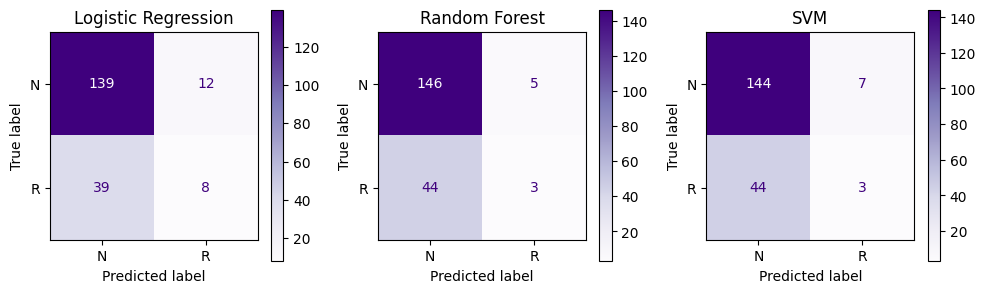

In [ ]:
model_results = {
    "Logistic Regression": lg_results,
    "Random Forest": rf_results,
    "SVM": svm_results
}

comparison = []

spec_all = [lg_specificity,rf_specificity,svm_specificity]

#display all measurements from all 3 models
for (modelname, modelresult), spec in zip(model_results.items(), spec_all):
  row = {"Model": modelname}
  for name, metric in zip(metricnames, metrickeys):
    scores = modelresult[metric]
    row[name] = f"{scores.mean():.3f} ± {scores.std():.3f}"
  row["Specificity"] = f"{spec:.3f}"
  comparison.append(row)
comparison_df = pd.DataFrame(comparison).set_index("Model")
display(comparison_df)

#display confusion matrices from all 3 models
fig, axes = plt.subplots(1, 3, figsize=(10, 3))
predictions = [lg_Y_pred, rf_Y_pred, svm_Y_pred]
model_names = ["Logistic Regression", "Random Forest", "SVM"]

for ax, pred, name in zip(axes, predictions, model_names):
    ConfusionMatrixDisplay.from_predictions(
        Y, pred,
        display_labels=["N", "R"],
        cmap="Purples",
        ax=ax
    )
    ax.set_title(name)

plt.tight_layout()
plt.show()

# **OLIVIA – Feature importance and comparison**

1. 5-fold Stratified Cross-validation of WDBC models
In order to compare with WPBC models

In [ ]:
from sklearn.model_selection import StratifiedKFold,cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
import pandas as pd
# Prepare the WDBC data
X_wdbc=x.copy()
y_wdbc=y["Diagnosis"].map({"B":0,"M":1})

# Set up 5-fold cross_validation
cv_wdbc=StratifiedKFold(n_splits=5,shuffle=True,random_state=42)

# Define the 3 models
models_wdbc = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=200))
    ]),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        random_state=42
    ),

    "SVM": Pipeline([
        ("scaler", StandardScaler()),
        ("model", SVC(kernel="linear", probability=True))
    ])
}

# Evaluate all 3 models
scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc",
    "average_precision": "average_precision"
}

wdbc_results={}
for name, model in models_wdbc.items():  #Take out the model name and the model itself one by one
  results=cross_validate(model,X_wdbc,y_wdbc,cv=cv_wdbc,scoring=scoring)
  wdbc_results[name]={"Accuracy":results["test_accuracy"].mean(),
            "Precision":results["test_precision"].mean(),
            "Recall":results["test_recall"].mean(),
            "F1":results["test_f1"].mean(),
            "ROC-AUC":results["test_roc_auc"].mean(),
            "PR-AUC":results["test_average_precision"].mean()}  #calculate the mean value and save in the dictionary

# Display the comparison
wdbc_comparison=pd.DataFrame(wdbc_results).T
display(wdbc_comparison.round(3))

2. Choose the best model (WDBC &WPBC)
---2.1 WDBC: Choose model based on ROC_AUC (We choose ROC_AUC because the main task of WDBC is diagnosis, we need to pay attention to the ability of the model to distinguish between benign and malgnant)



In [ ]:
best_wdbc_name=wdbc_comparison["ROC-AUC"].idxmax()
best_wdbc_model=models_wdbc[best_wdbc_name]
print("Best WDBC model:", best_wdbc_name)


---2.2 WPBC: Choose model based on PR-AUC

In [ ]:
# Store the existing WPBC model results
wpbc_results={
    "Logistic Regression": lg_results,
    "Random Forest": rf_results,
    "SVM": svm_results
}

# Store the existing WPBC models
models_wpbc={
    "Logistic Regression": log_reg,
    "Random Forest": rf,
    "SVM": svm
}

# Create a comparison table
wpbc_comparison=pd.DataFrame({
    name: {
        "Accuracy": result["test_accuracy"].mean(),
        "Precision": result["test_precision"].mean(),
        "Recall": result["test_recall"].mean(),
        "F1": result["test_f1"].mean(),
        "ROC-AUC": result["test_roc_auc"].mean(),
        "PR-AUC": result["test_average_precision"].mean()
    }
    for name, result in wpbc_results.items()
}).T

display(wpbc_comparison.round(3))

# Choose the best model
best_wpbc_name = wpbc_comparison["PR-AUC"].idxmax()

best_wpbc_model = models_wpbc[best_wpbc_name]

print("Best WPBC Model:", best_wpbc_name)

3. Feature Importance

In [ ]:
from sklearn.inspection import permutation_importance
from sklearn.base import clone
import numpy as np
import pandas as pd

def calculate_cv_importance(
    model,
    X,
    y,
    cv,
    scoring,
    n_repeats=30
):

    fold_importances = []

    # Repeat the process for each fold
    for fold, (train_idx, val_idx) in enumerate(cv.split(X, y)):

        # Split training and validation data
        X_train = X.iloc[train_idx]
        X_val = X.iloc[val_idx]

        y_train = y.iloc[train_idx]
        y_val = y.iloc[val_idx]

        # Create a fresh copy of the model
        model_copy = clone(model)

        # Train the model
        model_copy.fit(X_train, y_train)

        # Calculate permutation importance
        result = permutation_importance(
            model_copy,
            X_val,
            y_val,
            scoring=scoring,
            n_repeats=n_repeats,
            random_state=42 + fold,
            n_jobs=-1
        )

        fold_importances.append(result.importances_mean)

    # Calculate average importance across folds
    mean_importance = np.mean(fold_importances, axis=0)

    # Calculate standard deviation across folds
    std_importance = np.std(fold_importances, axis=0)

    # Create a DataFrame
    importance_df = pd.DataFrame({
        "Feature": X.columns,
        "Importance": mean_importance,
        "Std": std_importance
    })

    # Rank features from most to least important
    importance_df = importance_df.sort_values(
        by="Importance",
        ascending=False
    ).reset_index(drop=True)

    importance_df["Rank"] = importance_df.index + 1

    return importance_df

WDBC:

In [ ]:
wdbc_importance = calculate_cv_importance(
    model=best_wdbc_model,
    X=X_wdbc,
    y=y_wdbc,
    cv=cv_wdbc,
    scoring="roc_auc",
    n_repeats=30
)

display(wdbc_importance.head(10))

WPBC:

In [ ]:
wpbc_importance = calculate_cv_importance(
    model=best_wpbc_model,
    X=X_nuclear,
    y=Y,
    cv=cv,
    scoring="average_precision",
    n_repeats=30
)

display(wpbc_importance.head(10))

Create side by side comparison of the most important features for the 2 datasets

In [ ]:
# Comfirm the features are the same
print("WDBC features:", len(X_wdbc.columns))
print("WPBC features:", len(X_nuclear.columns))

print(
    "Are the features identical?",
    set(X_wdbc.columns) == set(X_nuclear.columns)
)

# Combine 2 importance tables
comparison_df = pd.merge(
    wdbc_importance,
    wpbc_importance,
    on="Feature",
    suffixes=("_WDBC", "_WPBC")
)

display(comparison_df.head())

# Judge which features are important to both datasets (Top10=Important)
comparison_df["Category"] = np.select(
    [
        (comparison_df["Rank_WDBC"] <= 10) &
        (comparison_df["Rank_WPBC"] <= 10),

        (comparison_df["Rank_WDBC"] <= 10) &
        (comparison_df["Rank_WPBC"] > 10),

        (comparison_df["Rank_WDBC"] > 10) &
        (comparison_df["Rank_WPBC"] <= 10)
    ],
    [
        "Important in both",
        "Diagnosis-specific",
        "Prognosis-related"
    ],
    default="Less important in both"
)

comparison_df = comparison_df.sort_values(
    by="Rank_WDBC"
)

display(comparison_df)

# List 4 situations separately
important_both = comparison_df[
    comparison_df["Category"] == "Important in both"
]

diagnosis_specific = comparison_df[
    comparison_df["Category"] == "Diagnosis-specific"
]

prognosis_related = comparison_df[
    comparison_df["Category"] == "Prognosis-related"
]

less_important = comparison_df[
    comparison_df["Category"] == "Less important in both"
]

print("Important in both:")
display(important_both[["Feature", "Rank_WDBC", "Rank_WPBC"]])

print("Diagnosis-specific:")
display(diagnosis_specific[["Feature", "Rank_WDBC"]])

print("Prognosis-related:")
display(prognosis_related[["Feature", "Rank_WPBC"]])

print("Less important in both:")
display(less_important[["Feature"]])

4. Side-by-side Bar charts (Top 10 Features importance)

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(16, 8))

# WDBC Top 10
wdbc_top10 = wdbc_importance.head(10)

axes[0].barh(
    wdbc_top10["Feature"],
    wdbc_top10["Importance"]
)

axes[0].set_title("WDBC: Breast Cancer Diagnosis")
axes[0].set_xlabel("Permutation Importance (ROC-AUC)")
axes[0].invert_yaxis()


# WPBC Top 10
wpbc_top10 = wpbc_importance.head(10)

axes[1].barh(
    wpbc_top10["Feature"],
    wpbc_top10["Importance"]
)

axes[1].set_title("WPBC: Breast Cancer Recurrence")
axes[1].set_xlabel("Permutation Importance (Average Precision)")
axes[1].invert_yaxis()

plt.tight_layout()
plt.show()

# **EHSAN – PCA and further analysis**

## PCA + Cross-Validation

## 1: Setup (DIAGNOSTIC)

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Diagnostic
X_wdbc = x.copy()
y_wdbc = y["Diagnosis"].map({"B": 0, "M": 1})
wdbc_labels = {0: "Benign", 1: "Malignant"}

# Prognostic
X_wpbc = X_nuclear.copy()
y_wpbc = Y.copy()
wpbc_labels = {0: "No recurrence", 1: "Recurrence"}

print("WDBC:", X_wdbc.shape, "| WPBC:", X_wpbc.shape)

WDBC: (569, 30) | WPBC: (198, 30)


## 2: Correlation

Dark red is close to +1 (they rise together), dark blue is close to −1 (one rises as the other falls), and white is close to 0 (no relationship).

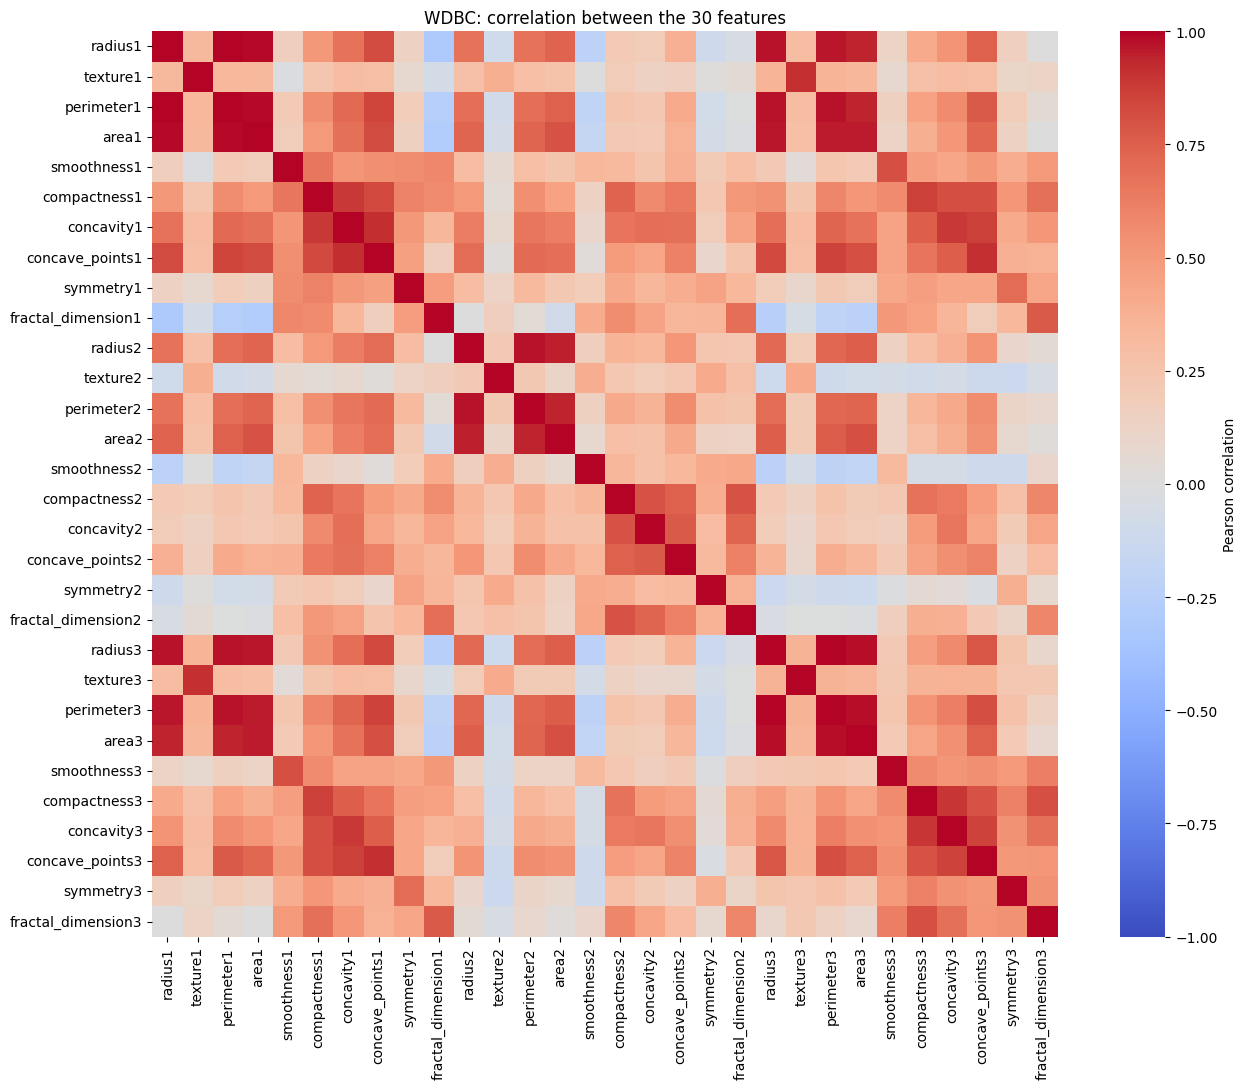

Feature pairs with |correlation| > 0.9: 21 out of 435


,,Correlation
radius1,perimeter1,0.998
radius3,perimeter3,0.994
radius1,area1,0.987
perimeter1,area1,0.987
radius3,area3,0.984
perimeter3,area3,0.978
radius2,perimeter2,0.973
perimeter1,perimeter3,0.970
radius1,radius3,0.970
perimeter1,radius3,0.969


In [ ]:
def plot_correlation(X, dataset_name):
    """Correlation heatmap of all features, plus a count of very strongly correlated pairs."""
    corr = X.corr()

    plt.figure(figsize=(14, 11))
    sns.heatmap(corr, cmap="coolwarm", center=0, vmin=-1, vmax=1, square=True,
                cbar_kws={"label": "Pearson correlation"})
    plt.title(f"{dataset_name}: correlation between the 30 features")
    plt.tight_layout()
    plt.show()

    upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
    strong_pairs = upper.stack()
    strong_pairs = strong_pairs[strong_pairs.abs() > 0.9].sort_values(ascending=False)
    print(f"Feature pairs with |correlation| > 0.9: {len(strong_pairs)} out of {upper.stack().shape[0]}")
    display(strong_pairs.head(10).round(3).to_frame("Correlation"))
    return corr


corr_wdbc = plot_correlation(X_wdbc, "WDBC")

## 3: Variance

The features are standardised first (mean 0, standard deviation 1). PCA follows variance, so without this, large-scale features such as area1 (values in the hundreds) would dominate the components just because of their units.

PCA is fitted here on the whole data set because this part is only exploration. For modelling (section 6), PCA is fitted inside each cross-validation fold instead.

The functions below are reused for WPBC in section 8.

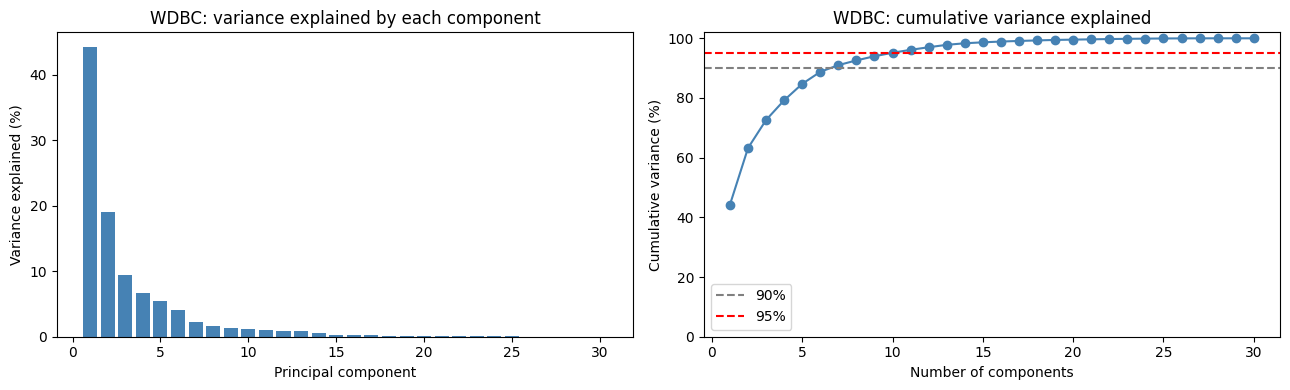

,Variance explained (%),Cumulative (%)
PC1,44.3,44.3
PC2,19.0,63.2
PC3,9.4,72.6
PC4,6.6,79.2
PC5,5.5,84.7
PC6,4.0,88.8
PC7,2.3,91.0
PC8,1.6,92.6
PC9,1.4,94.0
PC10,1.2,95.2


Components needed for 90% of the variance: 7 (out of 30)
Components needed for 95% of the variance: 10 (out of 30)


In [ ]:
# Imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

try:
    display
except NameError:
    display = print

# Check data exists
try:
    X_wdbc
except NameError:
    try:
        X_wdbc = x.copy()
        y_wdbc = y["Diagnosis"].map({"B": 0, "M": 1})
        wdbc_labels = {0: "Benign", 1: "Malignant"}
    except NameError:
        raise NameError("x / y not found: run Andreea's '1. Loading data' cell "
                        "(fetch_ucirepo(id=17)) first, then re-run this cell.")


def pca_variance_report(X, dataset_name):
    """Standardise X, fit PCA with all components, and plot/print the variance explained."""
    X_std = StandardScaler().fit_transform(X)
    pca = PCA().fit(X_std)

    var = pca.explained_variance_ratio_
    cum = np.cumsum(var)
    n90 = np.argmax(cum >= 0.90) + 1
    n95 = np.argmax(cum >= 0.95) + 1
    comps = np.arange(1, len(var) + 1)

    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    axes[0].bar(comps, var * 100, color="steelblue")
    axes[0].set(title=f"{dataset_name}: variance explained by each component",
                xlabel="Principal component", ylabel="Variance explained (%)")
    axes[1].plot(comps, cum * 100, marker="o", color="steelblue")
    axes[1].axhline(90, ls="--", color="grey", label="90%")
    axes[1].axhline(95, ls="--", color="red", label="95%")
    axes[1].set(title=f"{dataset_name}: cumulative variance explained",
                xlabel="Number of components", ylabel="Cumulative variance (%)", ylim=(0, 102))
    axes[1].legend()
    plt.tight_layout()
    plt.show()

    summary = pd.DataFrame({"Variance explained (%)": var[:10] * 100,
                            "Cumulative (%)": cum[:10] * 100},
                           index=[f"PC{i}" for i in range(1, 11)]).round(1)
    display(summary)
    print(f"Components needed for 90% of the variance: {n90} (out of {X.shape[1]})")
    print(f"Components needed for 95% of the variance: {n95} (out of {X.shape[1]})")
    return pca, X_std


def plot_pc_scatter(pca, X_std, y, labels, dataset_name):
    """Scatter plot of every patient on PC1 vs PC2, coloured by class."""
    scores = pca.transform(X_std)
    plt.figure(figsize=(7, 5))
    for value, name in labels.items():
        mask = (np.asarray(y) == value)
        plt.scatter(scores[mask, 0], scores[mask, 1], s=20, alpha=0.6, label=name)
    plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%} of variance)")
    plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%} of variance)")
    plt.title(f"{dataset_name}: patients on the first two principal components")
    plt.legend()
    plt.tight_layout()
    plt.show()


def plot_loadings(pca, feature_names, dataset_name, n_pcs=3):
    """Heatmap of loadings for the first n_pcs components, plus the top 5 features of each."""
    loadings = pd.DataFrame(pca.components_[:n_pcs].T, index=feature_names,
                            columns=[f"PC{i}" for i in range(1, n_pcs + 1)])
    plt.figure(figsize=(6, 10))
    sns.heatmap(loadings, cmap="coolwarm", center=0, annot=True, fmt=".2f",
                cbar_kws={"label": "Loading"})
    plt.title(f"{dataset_name}: feature loadings on PC1-PC{n_pcs}")
    plt.tight_layout()
    plt.show()

    for pc in loadings.columns:
        top = loadings[pc].abs().sort_values(ascending=False).head(5).index
        print(f"{pc} top features: " + ", ".join(f"{f} ({loadings.loc[f, pc]:+.2f})" for f in top))
    return loadings


pca_wdbc, X_wdbc_std = pca_variance_report(X_wdbc, "WDBC")

## 4: Patients on the first two components

Each point is one patient, projected from 30 dimensions down to 2. If the two classes form separate clusters, the main sources of variation in the data are related to the diagnosis.

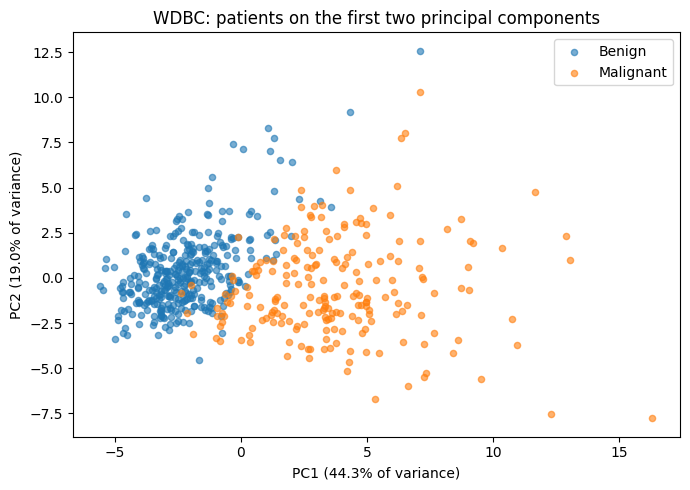

In [ ]:
plot_pc_scatter(pca_wdbc, X_wdbc_std, y_wdbc, wdbc_labels, "WDBC")

## 5: Which features make up each component

Values far from 0 (dark red or dark blue) mean a strong influence.

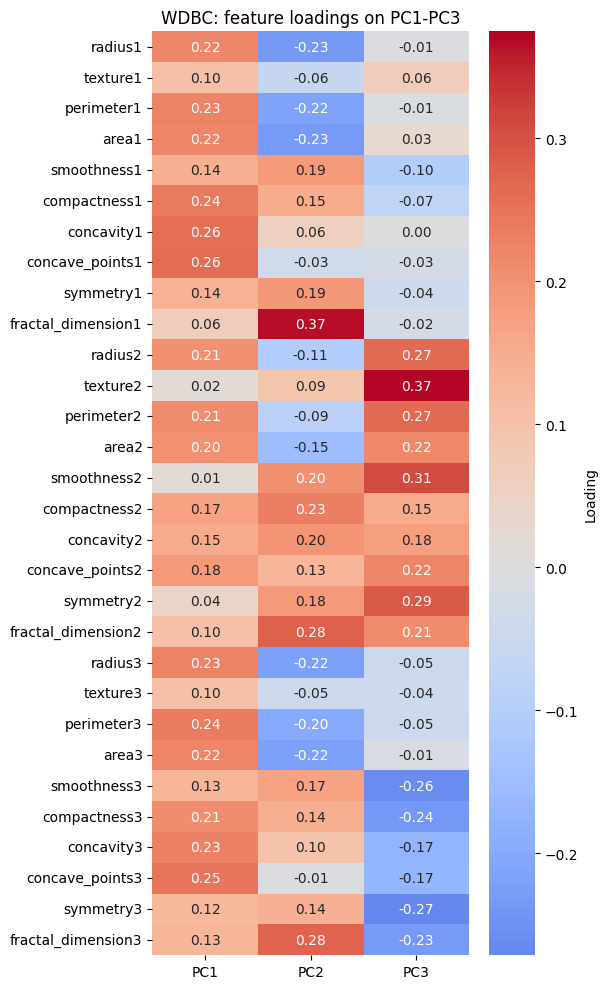

PC1 top features: concave_points1 (+0.26), concavity1 (+0.26), concave_points3 (+0.25), compactness1 (+0.24), perimeter3 (+0.24)
PC2 top features: fractal_dimension1 (+0.37), fractal_dimension2 (+0.28), fractal_dimension3 (+0.28), radius1 (-0.23), compactness2 (+0.23)
PC3 top features: texture2 (+0.37), smoothness2 (+0.31), symmetry2 (+0.29), symmetry3 (-0.27), radius2 (+0.27)


In [ ]:
loadings_wdbc = plot_loadings(pca_wdbc, X_wdbc.columns, "WDBC")

## 6: Models with and without PCA

Each of the three models is evaluated twice:

No PCA: all 30 standardised features
PCA: only the components that explain 95% of the variance

In [ ]:
# Imports
import pandas as pd
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import make_scorer, precision_score, recall_score
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

cv_pca = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

pca_scoring = {
    "Accuracy": "accuracy",
    "Precision": make_scorer(precision_score, zero_division=0),  # 0 instead of a warning if a fold has no positive predictions
    "Recall": "recall",
    "Specificity": make_scorer(recall_score, pos_label=0),  # specificity = recall of the negative class
    "F1 Score": "f1",
    "ROC-AUC": "roc_auc",
    "PR-AUC": "average_precision",
}

pca_models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "SVM": SVC(kernel="linear", random_state=42),
}


def compare_with_without_pca(X, y, n_components=0.95):
    """Cross-validate each model with and without PCA and return a table of mean ± std scores."""
    rows = []
    for model_name, model in pca_models.items():
        for use_pca in [False, True]:
            steps = [("scaler", StandardScaler())]
            if use_pca:
                steps.append(("pca", PCA(n_components=n_components)))
            steps.append(("model", clone(model)))

            results = cross_validate(Pipeline(steps), X, y, cv=cv_pca, scoring=pca_scoring)

            row = {"Model": model_name, "PCA": "Yes" if use_pca else "No"}
            for metric in pca_scoring:
                scores = results[f"test_{metric}"]
                row[metric] = f"{scores.mean():.3f} ± {scores.std():.3f}"
            rows.append(row)
    return pd.DataFrame(rows).set_index(["Model", "PCA"])


wdbc_pca_comparison = compare_with_without_pca(X_wdbc, y_wdbc)
display(wdbc_pca_comparison)

Accuracy      Precision         Recall  \
Model               PCA                                                
Logistic Regression No   0.974 ± 0.017  0.986 ± 0.018  0.944 ± 0.052   
                    Yes  0.977 ± 0.007  0.978 ± 0.028  0.962 ± 0.028   
Random Forest       No   0.954 ± 0.013  0.946 ± 0.039  0.934 ± 0.054   
                    Yes  0.951 ± 0.025  0.947 ± 0.057  0.925 ± 0.045   
SVM                 No   0.974 ± 0.022  0.976 ± 0.016  0.953 ± 0.049   
                    Yes  0.975 ± 0.007  0.977 ± 0.024  0.958 ± 0.028   

                           Specificity       F1 Score        ROC-AUC  \
Model               PCA                                                
Logistic Regression No   0.992 ± 0.011  0.963 ± 0.024  0.995 ± 0.005   
                    Yes  0.986 ± 0.018  0.969 ± 0.009  0.995 ± 0.006   
Random Forest       No   0.966 ± 0.027  0.938 ± 0.019  0.989 ± 0.008   
                    Yes  0.967 ± 0.039  0.934 ± 0.032  0.989 ± 0.009   
SVM                 No   0.986 ± 0.009  0.964 ± 0.031  0.994 ± 0.009   
                    Yes  0.986 ± 0.015  0.967 ± 0.009  0.995 ± 0.007   

                                PR-AUC  
Model               PCA                 
Logistic Regression No   0.994 ± 0.006  
                    Yes  0.994 ± 0.006  
Random Forest       No   0.987 ± 0.008  
                    Yes  0.984 ± 0.012  
SVM                 No   0.993 ± 0.009  
                    Yes  0.995 ± 0.007

## 7: How many components does a model need?

Instead of fixing the 95% threshold, this tests Logistic Regression with 1, 2, 3, ... 30 components and plots the cross-validated ROC-AUC and recall for each. The dashed lines show the scores without PCA. Recall matters most here, because a missed malignant case (false negative) is the most costly mistake.

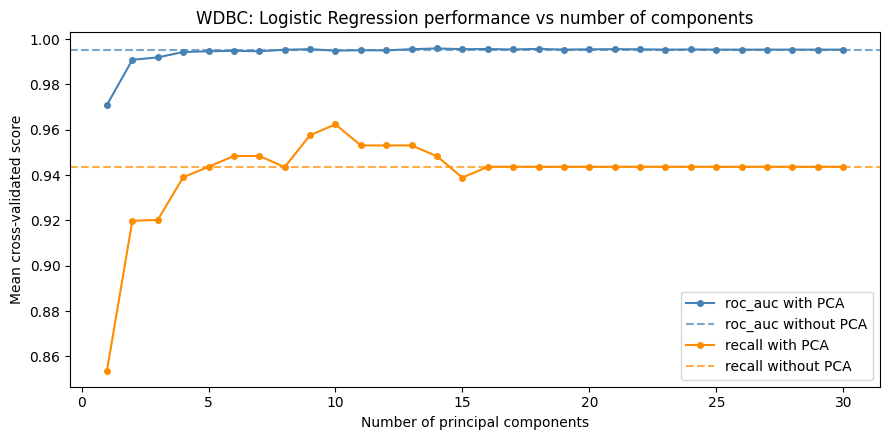

Best roc_auc: 0.996 with 9 components (without PCA: 0.995)
Best recall: 0.962 with 10 components (without PCA: 0.944)


In [ ]:
def components_sweep(X, y, dataset_name, metrics=("roc_auc", "recall")):
    """Cross-validated scores of Logistic Regression for every possible number of components."""
    ks = np.arange(1, X.shape[1] + 1)
    sweep = {m: [] for m in metrics}
    for k in ks:
        pipe = Pipeline([("scaler", StandardScaler()),
                         ("pca", PCA(n_components=k)),
                         ("model", LogisticRegression(max_iter=1000, random_state=42))])
        res = cross_validate(pipe, X, y, cv=cv_pca, scoring=list(metrics))
        for m in metrics:
            sweep[m].append(res[f"test_{m}"].mean())

    baseline = cross_validate(Pipeline([("scaler", StandardScaler()),
                                        ("model", LogisticRegression(max_iter=1000, random_state=42))]),
                              X, y, cv=cv_pca, scoring=list(metrics))

    plt.figure(figsize=(9, 4.5))
    for m, colour in zip(metrics, ["steelblue", "darkorange"]):
        plt.plot(ks, sweep[m], marker="o", ms=4, color=colour, label=f"{m} with PCA")
        plt.axhline(baseline[f"test_{m}"].mean(), ls="--", color=colour, alpha=0.7,
                    label=f"{m} without PCA")
    plt.xlabel("Number of principal components")
    plt.ylabel("Mean cross-validated score")
    plt.title(f"{dataset_name}: Logistic Regression performance vs number of components")
    plt.legend()
    plt.tight_layout()
    plt.show()

    table = pd.DataFrame(sweep, index=ks).round(3)
    table.index.name = "Components"
    for m in metrics:
        best_k = table[m].idxmax()
        print(f"Best {m}: {table.loc[best_k, m]:.3f} with {best_k} components "
              f"(without PCA: {baseline[f'test_{m}'].mean():.3f})")
    return table


wdbc_sweep = components_sweep(X_wdbc, y_wdbc, "WDBC")

## 8: PCA (PROGNOSTIC)

Repeat sections 2–7 again on the 198 recurrence patients.

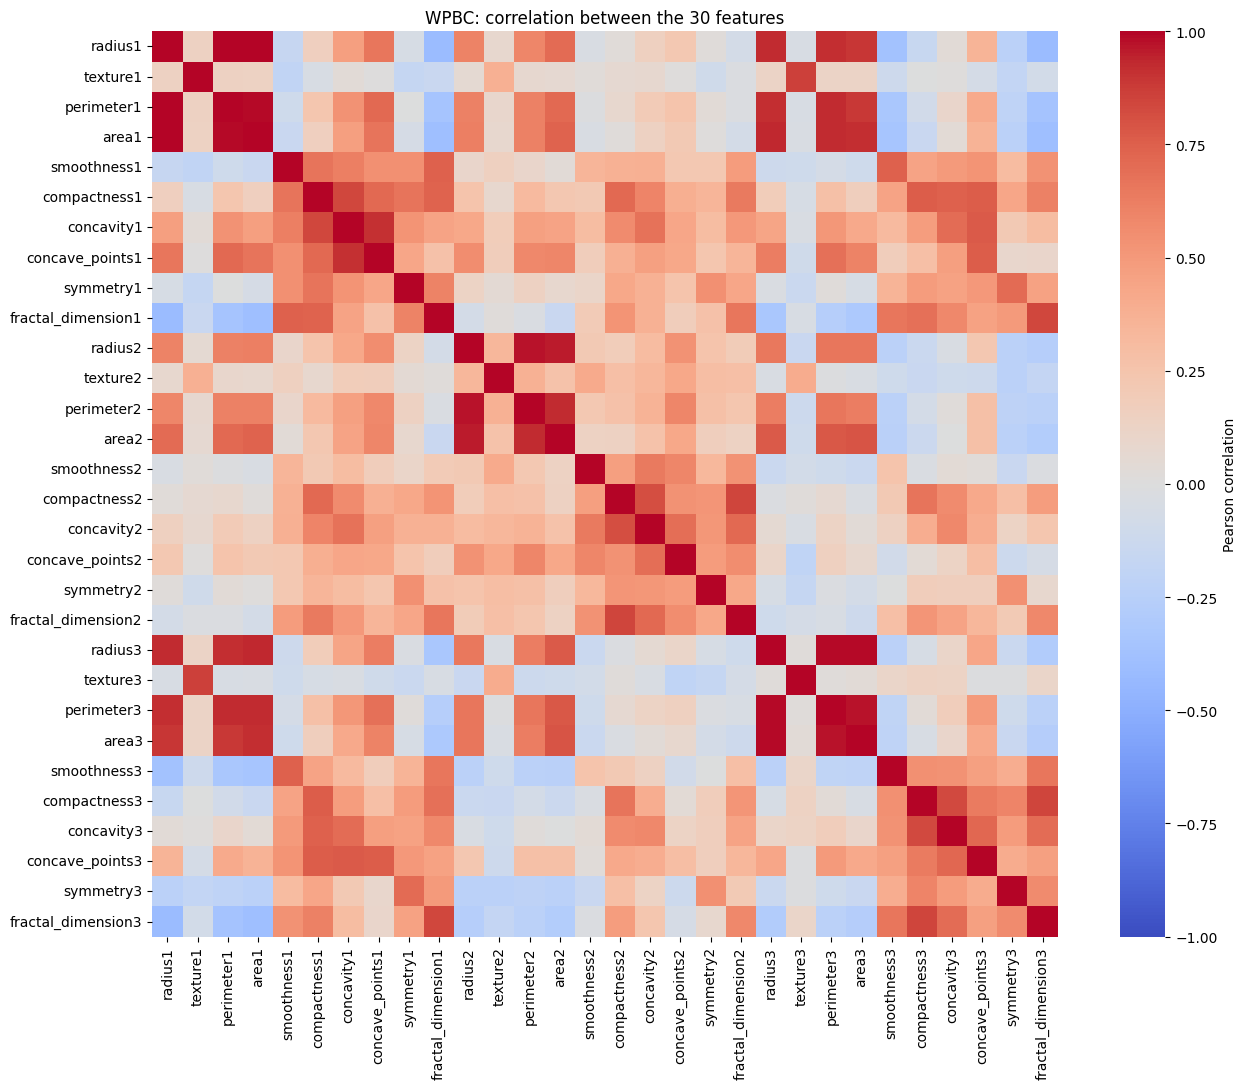

Feature pairs with |correlation| > 0.9: 17 out of 435


Correlation
radius1    perimeter1        0.996
           area1             0.993
perimeter1 area1             0.991
radius3    area3             0.988
           perimeter3        0.986
perimeter3 area3             0.974
radius2    perimeter2        0.973
           area2             0.957
area1      radius3           0.932
perimeter2 area2             0.930

In [ ]:
corr_wpbc = plot_correlation(X_wpbc, "WPBC")

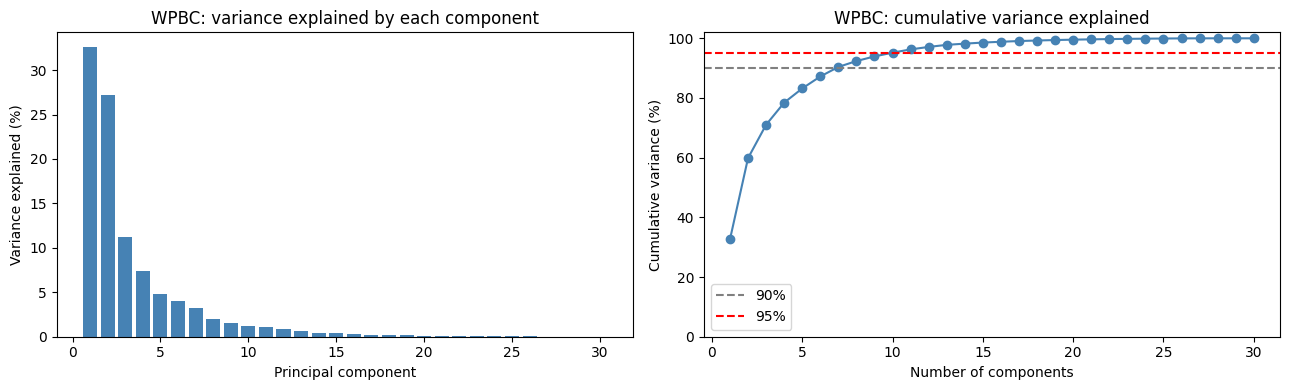

,Variance explained (%),Cumulative (%)
PC1,32.6,32.6
PC2,27.2,59.8
PC3,11.2,71.0
PC4,7.4,78.4
PC5,4.8,83.2
PC6,4.0,87.2
PC7,3.2,90.4
PC8,2.0,92.4
PC9,1.6,93.9
PC10,1.3,95.2


Components needed for 90% of the variance: 7 (out of 30)
Components needed for 95% of the variance: 10 (out of 30)


In [ ]:
pca_wpbc, X_wpbc_std = pca_variance_report(X_wpbc, "WPBC")

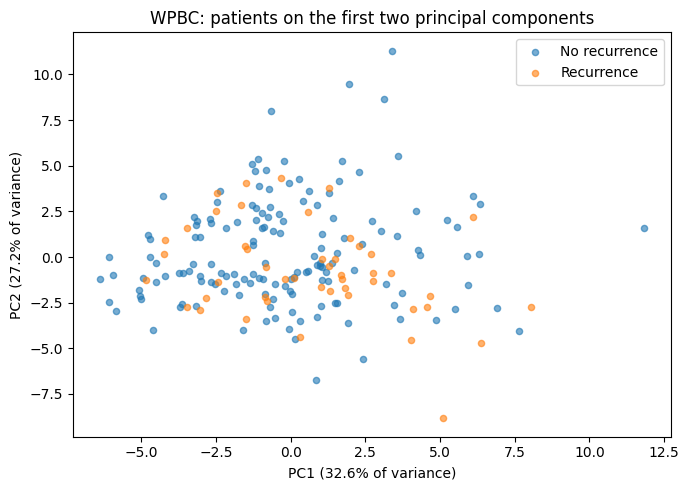

In [ ]:
plot_pc_scatter(pca_wpbc, X_wpbc_std, y_wpbc, wpbc_labels, "WPBC")

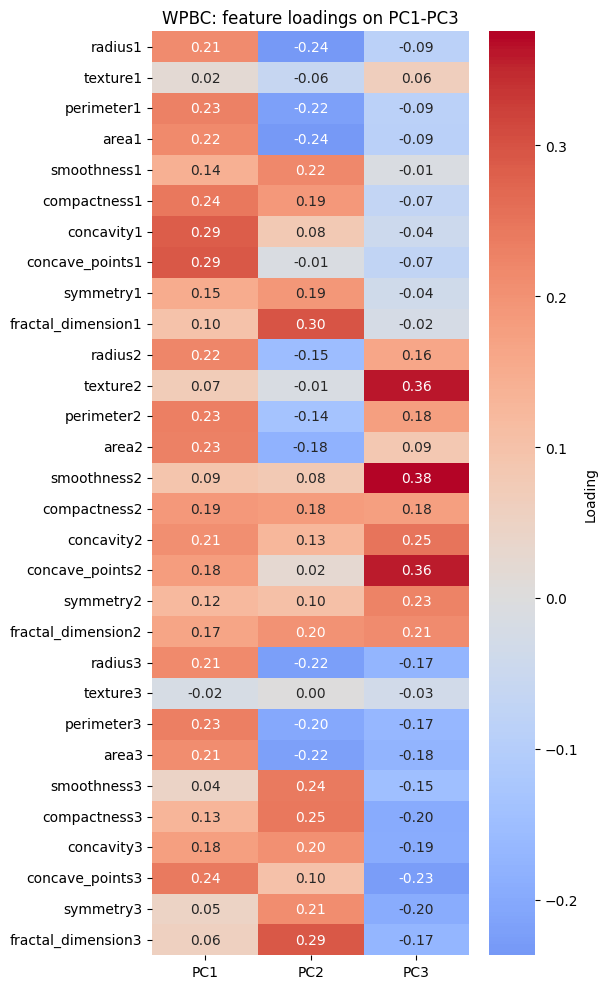

PC1 top features: concave_points1 (+0.29), concavity1 (+0.29), compactness1 (+0.24), concave_points3 (+0.24), perimeter3 (+0.23)
PC2 top features: fractal_dimension1 (+0.30), fractal_dimension3 (+0.29), compactness3 (+0.25), smoothness3 (+0.24), radius1 (-0.24)
PC3 top features: smoothness2 (+0.38), texture2 (+0.36), concave_points2 (+0.36), concavity2 (+0.25), concave_points3 (-0.23)


In [ ]:
loadings_wpbc = plot_loadings(pca_wpbc, X_wpbc.columns, "WPBC")

In [ ]:
wpbc_pca_comparison = compare_with_without_pca(X_wpbc, y_wpbc)
display(wpbc_pca_comparison)

Accuracy      Precision         Recall  \
Model               PCA                                                
Logistic Regression No   0.742 ± 0.031  0.294 ± 0.246  0.169 ± 0.152   
                    Yes  0.742 ± 0.031  0.200 ± 0.292  0.082 ± 0.117   
Random Forest       No   0.753 ± 0.029  0.300 ± 0.400  0.062 ± 0.081   
                    Yes  0.773 ± 0.018  0.283 ± 0.348  0.100 ± 0.126   
SVM                 No   0.742 ± 0.020  0.267 ± 0.226  0.064 ± 0.053   
                    Yes  0.763 ± 0.011  0.000 ± 0.000  0.000 ± 0.000   

                           Specificity       F1 Score        ROC-AUC  \
Model               PCA                                                
Logistic Regression No   0.920 ± 0.027  0.213 ± 0.185  0.620 ± 0.117   
                    Yes  0.947 ± 0.027  0.116 ± 0.167  0.590 ± 0.121   
Random Forest       No   0.967 ± 0.030  0.097 ± 0.122  0.580 ± 0.054   
                    Yes  0.980 ± 0.016  0.147 ± 0.184  0.566 ± 0.120   
SVM                 No   0.954 ± 0.017  0.103 ± 0.084  0.586 ± 0.051   
                    Yes  1.000 ± 0.000  0.000 ± 0.000  0.516 ± 0.067   

                                PR-AUC  
Model               PCA                 
Logistic Regression No   0.389 ± 0.118  
                    Yes  0.372 ± 0.129  
Random Forest       No   0.350 ± 0.078  
                    Yes  0.367 ± 0.092  
SVM                 No   0.343 ± 0.056  
                    Yes  0.293 ± 0.058

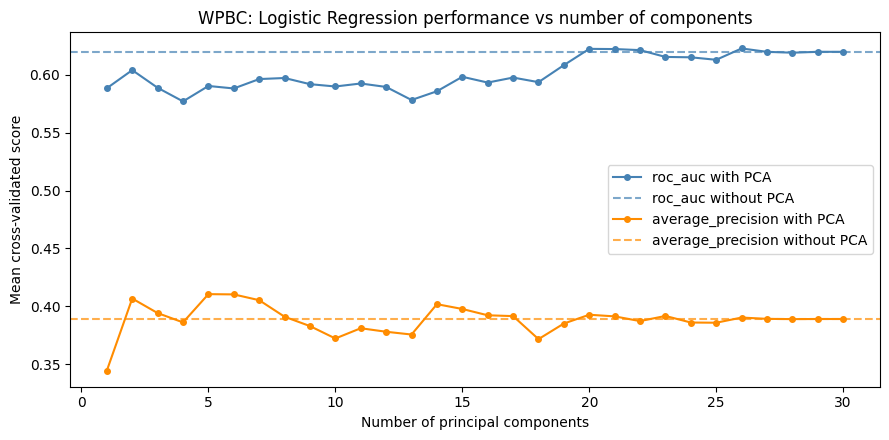

Best roc_auc: 0.623 with 26 components (without PCA: 0.620)
Best average_precision: 0.411 with 5 components (without PCA: 0.389)


In [ ]:
wpbc_sweep = components_sweep(X_wpbc, y_wpbc, "WPBC", metrics=("roc_auc", "average_precision"))